# Deal-Grove Thermal Oxidation Model for Silicon
A Python model of thermal oxidation of silicon using the Deal-Grove relation, x² + A·x = B·(t + τ). It computes oxide thickness against time and temperature for dry (O₂) and wet (H₂O) oxidation, the time needed to reach a target thickness, and multi-step sequences such as dry-wet-dry. The closed-form solution is checked against direct numerical integration, and the rate constants are compared with a second published source.

**Tools:** Python (NumPy, SciPy, Matplotlib). Runs in Google Colab with no installs.

**Author**: Kiranmayee Vaddepally, M.Tech, Quantum and Solid State Devices, IIT Hyderabad.

## 1. Inputs
Change `TEMPS`, `ORIENT` and `TARGET_nm` and re-run the plotting cells.

In [22]:
TEMPS = [900, 1000, 1100]   # deg C, for the thickness-vs-time plot
ORIENT = "100"              # silicon orientation: "100" or "111"
TARGET_nm = 100             # target oxide thickness for the time-to-grow plot

## 2. Model
Rate constants follow Arrhenius laws, B = C₁·exp(−E₁/kT) and B/A = C₂·exp(−E₂/kT). The constants below are for Si(111) at 1 atm; for Si(100) the linear rate B/A is divided by 1.68 and B is unchanged.

In [23]:
import numpy as np
from scipy.integrate import solve_ivp

K_B = 8.617333e-5  # eV/K

# ---- Inputs: Arrhenius constants for (111) Si, 1 atm  (TU Wien, Hollauer thesis Table 2.2) ----
# B = C1 exp(-E1/kT) [um^2/hr];  B/A = C2 exp(-E2/kT) [um/hr]
PARAMS = {
    "dry": dict(C1=7.72e2, E1=1.23, C2=6.23e6, E2=2.00),
    "wet": dict(C1=3.86e2, E1=0.78, C2=1.63e8, E2=2.05),
}
ORIENT_DIV = {"111": 1.0, "100": 1.68}   # (100): divide C2 by 1.68, B unchanged

def rate_constants(T_C, ambient="dry", orient="100"):
    """Return A [um], B [um^2/hr], B/A [um/hr] at temperature T_C (deg C)."""
    p = PARAMS[ambient]
    kT = K_B * (T_C + 273.15)
    B = p["C1"] * np.exp(-p["E1"] / kT)
    BA = p["C2"] / ORIENT_DIV[orient] * np.exp(-p["E2"] / kT)
    return B / BA, B, BA

def thickness(t_hr, T_C, ambient="dry", orient="100", x_i=0.0):
    """Oxide thickness [um] after t_hr: x^2 + A x = B t + (x_i^2 + A x_i)."""
    A, B, _ = rate_constants(T_C, ambient, orient)
    tau = (x_i**2 + A * x_i) / B
    return (A / 2) * (np.sqrt(1 + 4 * B * (np.asarray(t_hr) + tau) / A**2) - 1)

def time_to_grow(x_target, T_C, ambient="dry", orient="100", x_i=0.0):
    """Time [hr] to go from x_i to x_target: t = (x^2 - xi^2)/B + (x - xi)/(B/A)."""
    A, B, BA = rate_constants(T_C, ambient, orient)
    return (x_target**2 - x_i**2) / B + (x_target - x_i) / BA

def recipe(steps, orient="100", x_i=0.0, n=60):
    """steps = [(ambient, T_C, minutes), ...]; returns time [min] and thickness [um]."""
    t_all, x_all, t0, x0 = [0.0], [x_i], 0.0, x_i
    for amb, T, mins in steps:
        ts = np.linspace(0, mins / 60, n)[1:]
        xs = thickness(ts, T, amb, orient, x0)
        t_all += list(t0 + ts * 60); x_all += list(xs)
        t0 += mins; x0 = float(xs[-1])
    return np.array(t_all), np.array(x_all)

## 3. Check: closed form vs numerical integration
The Deal-Grove thickness must satisfy dx/dt = B/(A + 2x). Here we integrate that differential equation numerically and compare it with the closed-form solution.

In [24]:
# Check the closed-form solution against direct numerical integration of dx/dt = B/(A + 2x)
from scipy.integrate import solve_ivp
for amb, T in (("dry", 1000), ("wet", 1100)):
    A, B, BA = rate_constants(T, amb, "100")
    sol = solve_ivp(lambda t, x: B/(A + 2*x), [0, 2], [0.0], rtol=1e-10, atol=1e-12, dense_output=True)
    for t in (0.1, 0.5, 2.0):
        xc, xn = float(thickness(t, T, amb, "100")), float(sol.sol(t)[0])
        print(f"{amb} {T} C, t = {t} h: closed form {xc*1000:.4f} nm, numerical {xn*1000:.4f} nm")

dry 1000 C, t = 0.1 h: closed form 4.4056 nm, numerical 4.4056 nm
dry 1000 C, t = 0.5 h: closed form 20.6174 nm, numerical 20.6174 nm
dry 1000 C, t = 2.0 h: closed form 69.1928 nm, numerical 69.1928 nm
wet 1100 C, t = 0.1 h: closed form 156.3242 nm, numerical 156.3242 nm
wet 1100 C, t = 0.5 h: closed form 431.3451 nm, numerical 431.3451 nm
wet 1100 C, t = 2.0 h: closed form 941.8640 nm, numerical 941.8640 nm


## 4. Check: rate constants vs a second source
The Arrhenius constants come from one reference (TU Wien). Here they are compared with the tabulated rate constants in a second, independent reference (CityU AP6120 ch. 4) at the same temperatures, for Si(111).

In [25]:
# Rate constants from CityU AP6120 ch. 4, Tables 4.1 (wet) and 4.2 (dry): (T, A, B, B/A)
cityu = {"wet": [(1100, 0.11, 0.510, 4.64), (1000, 0.226, 0.287, 1.27), (920, 0.50, 0.203, 0.406)],
         "dry": [(1200, 0.040, 0.045, 1.12), (1100, 0.090, 0.027, 0.30), (1000, 0.165, 0.0117, 0.071),
                 (920, 0.235, 0.0049, 0.0208), (800, 0.370, 0.0011, 0.0030)]}
print(f"{'ambient':8s}{'T (C)':>7s}{'B model':>10s}{'B table':>10s}{'diff':>7s}{'B/A model':>11s}{'B/A table':>11s}{'diff':>7s}")
for amb, rows in cityu.items():
    for T, A_t, B_t, BA_t in rows:
        A, B, BA = rate_constants(T, amb, "111")
        print(f"{amb:8s}{T:7d}{B:10.4g}{B_t:10.4g}{100*(B/B_t-1):+6.0f}%{BA:11.4g}{BA_t:11.4g}{100*(BA/BA_t-1):+6.0f}%")

ambient   T (C)   B model   B table   diff  B/A model  B/A table   diff
wet        1100    0.5294      0.51    +4%      4.878       4.64    +5%
wet        1000    0.3155     0.287   +10%      1.251       1.27    -1%
wet         920    0.1959     0.203    -4%     0.3574      0.406   -12%
dry        1200   0.04783     0.045    +6%      0.896       1.12   -20%
dry        1100   0.02362     0.027   -13%     0.2845        0.3    -5%
dry        1000   0.01044    0.0117   -11%    0.07542      0.071    +6%
dry         920  0.004923    0.0049    +0%    0.02221     0.0208    +7%
dry         800  0.001292    0.0011   +17%   0.002523      0.003   -16%


The Arrhenius fit agrees with the tabulated values within about 20% in the worst case and typically within 10%. Rate constants in the literature vary by this much between sources and fits, so thicknesses from this model are good to roughly that level.

## 5. Oxide thickness vs time

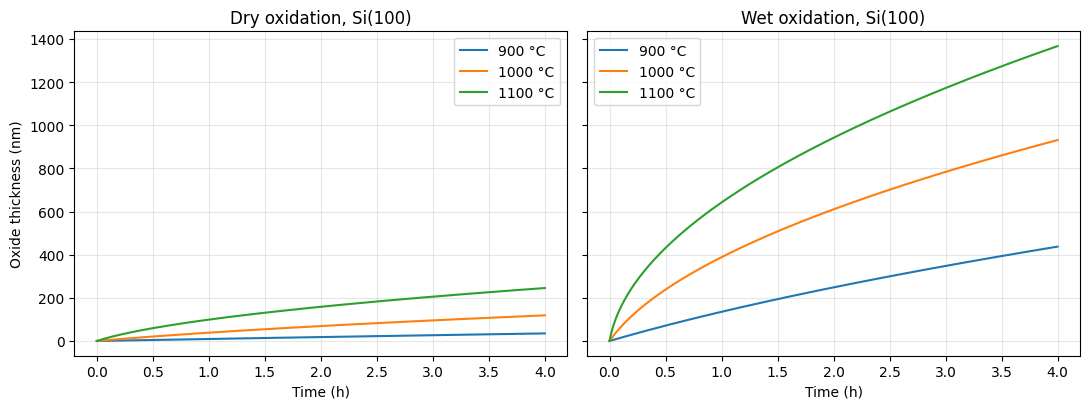

In [26]:
import matplotlib.pyplot as plt
t = np.linspace(0, 4, 400)  # hours
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, amb in zip(axs, ("dry", "wet")):
    for T in TEMPS:
        ax.plot(t, thickness(t, T, amb, ORIENT, 0.0)*1000, label=f"{T} °C")
    ax.set_title(f"{amb.capitalize()} oxidation, Si({ORIENT})")
    ax.set_xlabel("Time (h)"); ax.grid(alpha=.3); ax.legend()
axs[0].set_ylabel("Oxide thickness (nm)")
plt.tight_layout(); plt.show()

## 6. Time to grow a target oxide

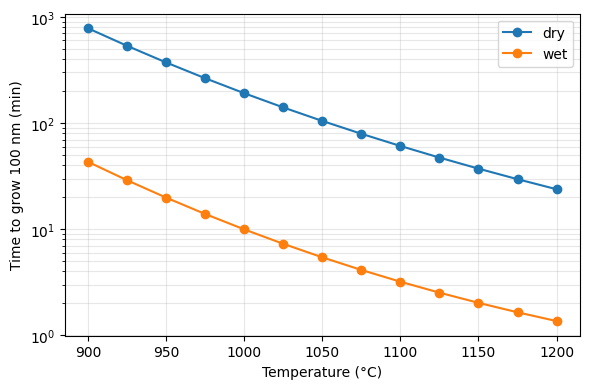

1000 C: dry 191 min, wet 10 min for 100 nm
1100 C: dry 61 min, wet 3 min for 100 nm


In [27]:
Ts = np.arange(900, 1201, 25)
fig, ax = plt.subplots(figsize=(6, 4))
for amb in ("dry", "wet"):
    ax.semilogy(Ts, [time_to_grow(TARGET_nm/1000, T, amb, ORIENT)*60 for T in Ts], "o-", label=amb)
ax.set_xlabel("Temperature (°C)"); ax.set_ylabel(f"Time to grow {TARGET_nm} nm (min)")
ax.grid(alpha=.3, which="both"); ax.legend(); plt.tight_layout(); plt.show()
for T in (1000, 1100):
    print(f"{T} C: dry {time_to_grow(TARGET_nm/1000, T, 'dry', ORIENT)*60:.0f} min, wet {time_to_grow(TARGET_nm/1000, T, 'wet', ORIENT)*60:.0f} min for {TARGET_nm} nm")

## 7. Multi-step sequence (dry-wet-dry)
After each step the model carries the existing oxide thickness into the next step, which is the role of the initial-thickness offset τ in the Deal-Grove relation. This is an illustrative example, not a real fab recipe.

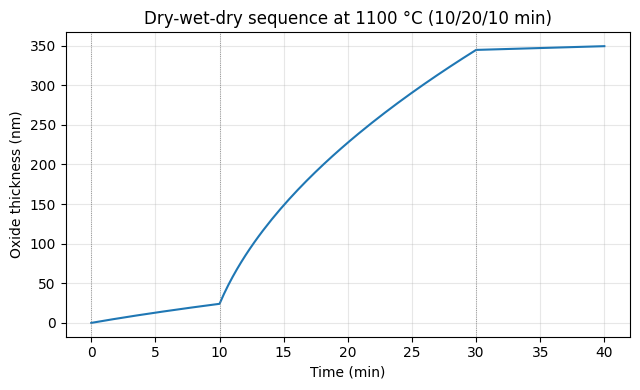

Final thickness after the sequence: 349 nm


In [28]:
steps = [("dry", 1100, 10), ("wet", 1100, 20), ("dry", 1100, 10)]   # (ambient, deg C, minutes)
tt, xx = recipe(steps, ORIENT)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(tt, xx*1000)
edge = 0
for amb, T, m in steps:
    ax.axvline(edge, color="gray", lw=.6, ls=":"); edge += m
ax.set_xlabel("Time (min)"); ax.set_ylabel("Oxide thickness (nm)"); ax.grid(alpha=.3)
ax.set_title("Dry-wet-dry sequence at 1100 °C (10/20/10 min)")
plt.tight_layout(); plt.show()
print(f"Final thickness after the sequence: {xx[-1]*1000:.0f} nm")

## 8. What this shows
- Wet oxidation grows oxide much faster than dry at the same temperature, because water diffuses through the oxide more readily than oxygen.
- Growth is linear (reaction-limited) for thin oxides and parabolic (diffusion-limited) for thick ones. Temperature raises both rates.
- Si(100) oxidizes more slowly than Si(111) in the linear regime, with the same parabolic rate.
- A multi-step sequence is modelled by carrying the oxide thickness from one step into the next.
## 9. Sources
- CityU AP6120, chapter 4 (oxidation): https://www.cityu.edu.hk/phy/appkchu/AP6120/4.PDF (Tables 4.1 and 4.2)
- TU Wien, Hollauer thesis, Deal-Grove model and Table 2.2: https://www.iue.tuwien.ac.at/phd/hollauer/node16.html
- Original model: B. E. Deal and A. S. Grove, J. Appl. Phys. 36, 3770 (1965).

## 10. Assumptions and limitations
- The model underestimates dry oxide growth for thicknesses below about 25 nm, where an extra fast initial growth regime exists. Results for very thin dry oxides are not reliable.
- Constant temperature in each step, instant ramp, and pure O₂ or H₂O at 1 atm. No ramp-up, no pressure dependence and no doping dependence.
- Silicon consumption (about 0.44 of the oxide thickness) is not tracked.
- This is a first-principles model of the basic physics, not a replacement for a process simulator.